(344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
4050.0
Male


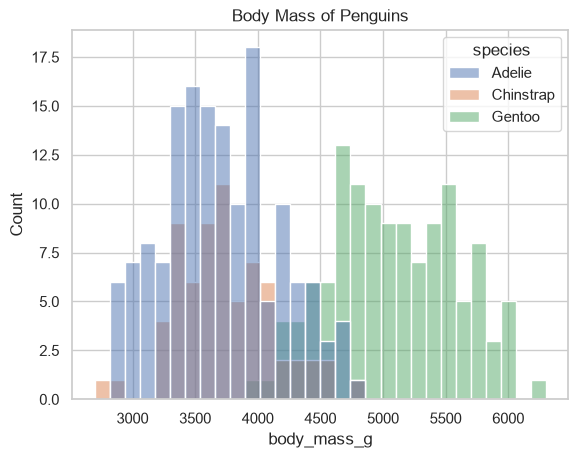

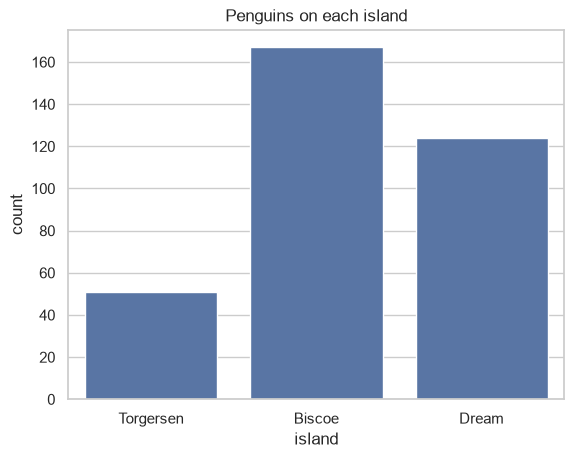

Q1: 3550.0  Q3: 4750.0  IQR: 1200.0
Above 6550.0 is an outlier
Number of outliers: 0


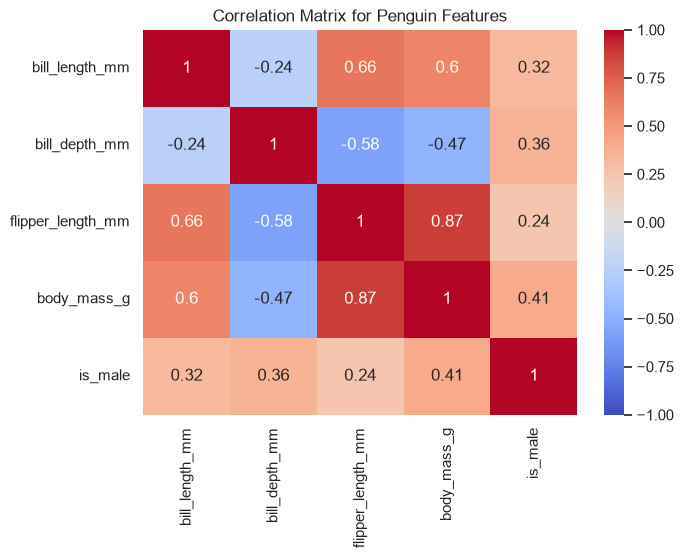

Average body mass by species:
species
Adelie       3700.7
Chinstrap    3733.1
Gentoo       5076.0
Name: body_mass_g, dtype: float64


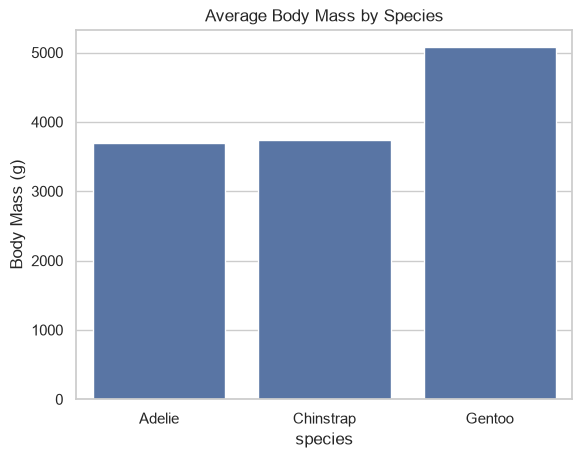

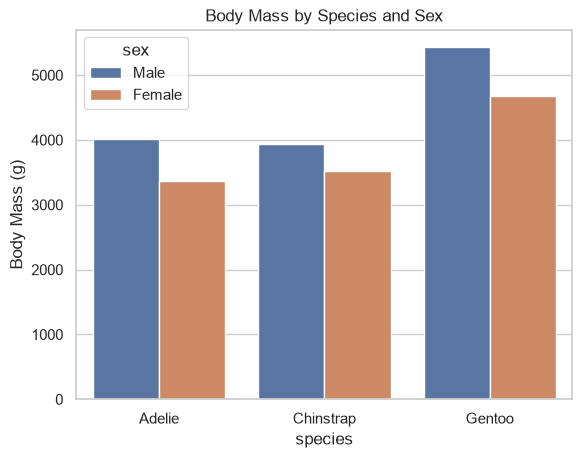

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Read penguins.csv. If the file is not here, download it once and save it.
try:
    df = pd.read_csv("penguins.csv")
except FileNotFoundError:
    sns.load_dataset("penguins").to_csv("penguins.csv", index=False)   # needs internet
    df = pd.read_csv("penguins.csv")

df.head()

print(df.shape)

df.info()

df.describe().round(1)

df.isna().sum()

print(df["species"].value_counts())

# Drop rows where all key measurement columns are missing
df = df.dropna(subset=["bill_length_mm", "body_mass_g"])

print(df["body_mass_g"].median())
print(df["sex"].mode()[0])

# Fill missing values with median for numerical and mode for categorical columns
df["bill_length_mm"] = df["bill_length_mm"].fillna(df["bill_length_mm"].median())
df["bill_depth_mm"] = df["bill_depth_mm"].fillna(df["bill_depth_mm"].median())
df["flipper_length_mm"] = df["flipper_length_mm"].fillna(df["flipper_length_mm"].median())
df["body_mass_g"] = df["body_mass_g"].fillna(df["body_mass_g"].median())
df["sex"] = df["sex"].fillna(df["sex"].mode()[0])

df.isna().sum()

# Feature Engineering
df["body_mass_kg"] = df["body_mass_g"] / 1000

df["size_group"] = np.where(df["body_mass_g"] < 4000, "Small", "Large")

df["is_male"] = np.where(df["sex"] == "Male", 1, 0)

df[["species", "island", "bill_length_mm", "body_mass_g", "body_mass_kg", "size_group", "is_male"]].head()

# Visualizations: Histograms & Countplots
sns.histplot(data=df, x="body_mass_g", bins=30, hue="species")
plt.title("Body Mass of Penguins")
plt.show()

sns.countplot(data=df, x="island")
plt.title("Penguins on each island")
plt.show()

# Outlier Detection using IQR (similar to Fare)
q1 = df["body_mass_g"].quantile(0.25)
q3 = df["body_mass_g"].quantile(0.75)
iqr = q3 - q1

high = q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", round(iqr, 1))
print("Above", round(high, 1), "is an outlier")
outliers = df[df["body_mass_g"] > high]
print("Number of outliers:", len(outliers))
outliers.sort_values("body_mass_g", ascending=False).head()

# Correlation Matrix Heatmap
cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "is_male"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix for Penguin Features")
plt.show()

# Groupbys and Barplots
print("Average body mass by species:")
print(df.groupby("species")["body_mass_g"].mean().round(1))

sns.barplot(data=df, x="species", y="body_mass_g", errorbar=None)
plt.title("Average Body Mass by Species")
plt.ylabel("Body Mass (g)")
plt.savefig("mass_by_species.png", dpi=150, bbox_inches="tight")
plt.show()

sns.barplot(data=df, x="species", y="body_mass_g", hue="sex", errorbar=None)
plt.title("Body Mass by Species and Sex")
plt.ylabel("Body Mass (g)")
plt.savefig("mass_by_species_and_sex.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Read penguins.csv. If the file is not here, download it once and save it.
try:
    df = pd.read_csv("penguins.csv")
except FileNotFoundError:
    sns.load_dataset("penguins").to_csv("penguins.csv", index=False)   # needs internet
    df = pd.read_csv("penguins.csv")

df.head()

: 

In [ ]:
print(df.shape)

In [ ]:
df.info()

In [ ]:
df.describe().round(1)

In [ ]:
df.isna().sum()

In [ ]:
print(df["species"].value_counts())

In [ ]:
# Drop rows where all key measurement columns are missing
df = df.dropna(subset=["bill_length_mm", "body_mass_g"])

print(df["body_mass_g"].median())
print(df["sex"].mode()[0])

# Fill missing values with median for numerical and mode for categorical columns
df["bill_length_mm"] = df["bill_length_mm"].fillna(df["bill_length_mm"].median())
df["bill_depth_mm"] = df["bill_depth_mm"].fillna(df["bill_depth_mm"].median())
df["flipper_length_mm"] = df["flipper_length_mm"].fillna(df["flipper_length_mm"].median())
df["body_mass_g"] = df["body_mass_g"].fillna(df["body_mass_g"].median())
df["sex"] = df["sex"].fillna(df["sex"].mode()[0])

df.isna().sum()

In [ ]:
# Feature Engineering
df["body_mass_kg"] = df["body_mass_g"] / 1000

df["size_group"] = np.where(df["body_mass_g"] < 4000, "Small", "Large")

df["is_male"] = np.where(df["sex"] == "Male", 1, 0)

df[["species", "island", "bill_length_mm", "body_mass_g", "body_mass_kg", "size_group", "is_male"]].head()


In [ ]:
# Visualizations: Histograms & Countplots
sns.histplot(data=df, x="body_mass_g", bins=30, hue="species")
plt.title("Body Mass of Penguins")
plt.show()

sns.countplot(data=df, x="island")
plt.title("Penguins on each island")
plt.show()

In [ ]:
# Outlier Detection using IQR (similar to Fare)
q1 = df["body_mass_g"].quantile(0.25)
q3 = df["body_mass_g"].quantile(0.75)
iqr = q3 - q1

high = q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", round(iqr, 1))
print("Above", round(high, 1), "is an outlier")
outliers = df[df["body_mass_g"] > high]
print("Number of outliers:", len(outliers))
outliers.sort_values("body_mass_g", ascending=False).head()


In [ ]:
# Correlation Matrix Heatmap
cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "is_male"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix for Penguin Features")
plt.show()

In [ ]:
# Groupbys and Barplots
print("Average body mass by species:")
print(df.groupby("species")["body_mass_g"].mean().round(1))

sns.barplot(data=df, x="species", y="body_mass_g", errorbar=None)
plt.title("Average Body Mass by Species")
plt.ylabel("Body Mass (g)")
plt.savefig("mass_by_species.png", dpi=150, bbox_inches="tight")
plt.show()

sns.barplot(data=df, x="species", y="body_mass_g", hue="sex", errorbar=None)
plt.title("Body Mass by Species and Sex")
plt.ylabel("Body Mass (g)")
plt.savefig("mass_by_species_and_sex.png", dpi=150, bbox_inches="tight")
plt.show()